# Production run — RMSE, IA and MNB per administrative unit

Scores the calibrated production run (SIMPLACE and torchcrop, both on the
per-region calibrated crops) against the references the calibration was fitted
to, **on the basis it was fitted on**:

| Target | Reference | Correction | Years |
|---|---|---|---|
| Grain yield | CyBench, NUTS-2/3 | × (1 − 0.135) to dry matter | 2000–2021 |
| Emergence | CLMS `CPMCE` | −6.0 d (PEP725) | 2017–2024 |
| Harvest | CLMS `CPMCH` | +18.7 d (PEP725) | 2017–2024 |
| Emergence → harvest | CLMS | +24.7 d (the sum) | 2017–2024 |

A 10 km cell is assigned to the unit containing its centre and units are
equal-weight means of their cells; dates are averaged on the circle.

**Metrics.** Error is simulated − observed.

* **RMSE** in the target's unit.
* **IA**, Willmott's index of agreement, 0–1: 1 is a perfect match. Unlike R²
  it also penalises an offset or a wrong amplitude.
* **MNB**, mean normalised bias `mean((S − O) / O)` in %. It is defined only for
  ratio-scale quantities (yield, season length). A day-of-year has no natural
  zero, so for **emergence and harvest the third map is the bias in days**.

Each unit is scored over its own seasons, and needs at least
`MIN_YEARS` of them. With CLMS's eight seasons that is a short series, so the
per-unit IA is noisy; the pooled table at the end is the stable summary.

Only an observed-weather run can be scored year by year — a CMIP6 year is a
sample of that model's climate, not the observed season of the same number, and
`check_year_matched` refuses such a run.

## 0. Setup

In [1]:
import logging
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cropmodelling4eu.evaluation import production as prod
from cropmodelling4eu.evaluation.fullrun import load_runs
from cropmodelling4eu.evaluation.plots import EUROPE_PROJECTION, country_choropleth, save
from cropmodelling4eu.evaluation.regions import load_admin_polygons
import colormaps as cmaps

from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, use_poster_style

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s",
                    force=True)
# The TorchCrop poster's look: Segoe UI (Selawik fallback), black text and
# spines, SIMPLACE grey and TorchCrop teal (evaluation.style.use_poster_style).
PALETTE = use_poster_style()

#: Override with PRODUCTION_RUN_DIR / CALIBRATION_DIR in the environment.
RUN = prod.PRODUCTION_RUN_DIR
CALIBRATION = prod.CALIBRATION_DIR
prod.check_year_matched(RUN)

YEARS = (2000, 2024)
MIN_YEARS = prod.MIN_YEARS
OUT = Path(os.environ.get("PRODUCTION_EVAL_DIR", RUN / "evaluation"))
FIGURES, TABLES = OUT / "figures", OUT / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

MODELS = {"simplace": "SIMPLACE", "torchcrop": "TorchCrop"}


def _limit(values: pd.Series, q: float = 0.95) -> float:
    """Symmetric colour limit: the q-quantile of |values|."""
    finite = values.replace([np.inf, -np.inf], np.nan).dropna()
    return float(finite.abs().quantile(q)) if len(finite) else 1.0

print(f"run         : {RUN}")
print(f"calibration : {CALIBRATION}")
print(f"outputs     : {OUT}")

run         : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx
calibration : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/winter_wheat_2000_2024_euval/calibration
outputs     : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx/evaluation


## 1. Load the runs and the corrected references

In [2]:
runs = load_runs(RUN / "simplace" / "simplace_europe.parquet",
                 RUN / "torchcrop" / "torchcrop_europe.parquet", years=YEARS)
cell_to_adm = pd.read_parquet(CALIBRATION / "cell_to_adm.parquet")
countries = sorted(cell_to_adm["adm_country"].dropna().unique())
reference = prod.load_reference(countries, YEARS)
polygons = load_admin_polygons(countries)

paired = prod.pair_units(runs, reference, cell_to_adm, CALIBRATION)
pd.DataFrame({
    model: {
        "cell-seasons": len(frame),
        "cells": frame["SimplaceID"].nunique(),
        "years": f"{frame['year'].min()}-{frame['year'].max()}",
        "paired units": paired.loc[paired["model"] == model, "adm_id"].nunique(),
    }
    for model, frame in runs.items()
}).T

WARNING cropmodelling4eu.evaluation.torchcrop: 183 of 1711524 rows (0.01%) never reached maturity; their dates are NaN
WARNING cropmodelling4eu.evaluation.fullrun: simplace: 5332 of 1716679 rows (0.31%) carry a season shorter than 150 days -- the (0, 365] wrap in collect.to_run_schema, not a 3-day crop. Their durations are dropped; their dates are kept


,cell-seasons,cells,years,paired units
torchcrop,1711524,68685,2000-2024,843
simplace,1716679,68685,2000-2024,843


How many paired unit-years each target has, by the calibration split it fell
in. `unused` rows are units or years the calibration never saw: for yield they
are mostly units with no calibration region, for phenology the CyBench units
whose CLMS series was gated out of the calibration pool.

In [3]:
one_model = paired[paired["model"] == "simplace"]
pd.DataFrame({
    t.label: one_model.dropna(subset=[t.sim_col, t.obs_col])[f"split_{t.key}"].value_counts()
    for t in prod.TARGETS
}).fillna(0).astype(int).T

,test,train,unused,val
Grain yield,2197,12161,7,564
Emergence,1554,3591,0,666
Harvest,1554,3591,0,666
Emergence to harvest,1554,3591,0,666


## 2. Climatological means

Each unit's mean over **its own paired seasons**, the same unit-years on both
sides, so the bottom row is a climatological bias with no sampling difference
in it. The top row shares one colour scale (5th–95th percentile of all three
panels). Dates are circular means unwrapped about the domain mean, so the scale
has no seam at New Year: an emergence of DOY 370 is 5 January.

In [4]:
# Means: YlGnBu in 11 steps, lightest = lowest. Its own first quarter is
# near-white and vanishes against the map's land and sea (OKLab dE 5), so the
# ramp starts at 0.28, a pale green 10+ from both. Differences: NCL's
# BlueDarkOrange18 (colormaps package), teal = model low or early, brown = high
# or late.
from matplotlib.colors import ListedColormap

CLIM_CMAP = ListedColormap(plt.get_cmap("YlGnBu")(np.linspace(0.28, 1.0, 11)), name="YlGnBu_11")
DIFF_CMAP = cmaps.BlueDarkOrange18
climatology = prod.unit_climatology(paired, min_years=MIN_YEARS)
climatology.to_csv(TABLES / "unit_climatology.csv", index=False)


def climatology_maps(target: prod.Target):
    clim = climatology[climatology["target"] == target.key]
    observed = clim.drop_duplicates("adm_id").set_index("adm_id")["obs"]
    unit = "DOY" if target.circular else target.unit
    lo, hi = np.nanpercentile(np.r_[observed, clim["sim"]], [5, 95])
    fig, axes = plt.subplots(2, 3, figsize=(13.0, 9.6),
                             subplot_kw={"projection": EUROPE_PROJECTION})
    panels = [("Observed", observed),
              *[(label, clim[clim["model"] == m].set_index("adm_id")["sim"])
                for m, label in MODELS.items()]]
    for ax, (label, values) in zip(axes[0], panels):
        country_choropleth(polygons, values, key_col="adm_id", diverging=False,
                           cmap=CLIM_CMAP, vmin=lo, vmax=hi, linewidth=0.15,
                           title=label, cbar_label=f"{target.label} ({unit})", ax=ax)
    diff_unit = "days" if target.circular else target.unit
    limit = _limit(clim["diff"])
    axes[1, 0].set_visible(False)
    for ax, (model, label) in zip(axes[1, 1:], MODELS.items()):
        values = clim[clim["model"] == model].set_index("adm_id")["diff"]
        country_choropleth(polygons, values, key_col="adm_id", diverging=True, vmax=limit,
                           cmap=DIFF_CMAP, linewidth=0.15, title=f"{label} − observed",
                           cbar_label=f"Difference ({diff_unit})", ax=ax)
        ax.text(0.03, 0.03, f"median {values.median():+.2f}", transform=ax.transAxes,
                fontsize=10, color="black",
                bbox={"facecolor": PALETTE["surface"], "edgecolor": "none", "alpha": 0.85, "pad": 2})
    source = "CyBench" if target.key == "yield" else "corrected CLMS"
    fig.suptitle(f"{target.label} — climatological mean per unit vs {source}", y=0.995)
    fig.tight_layout()
    save(fig, f"climatology_{target.key}", FIGURES)
    return fig

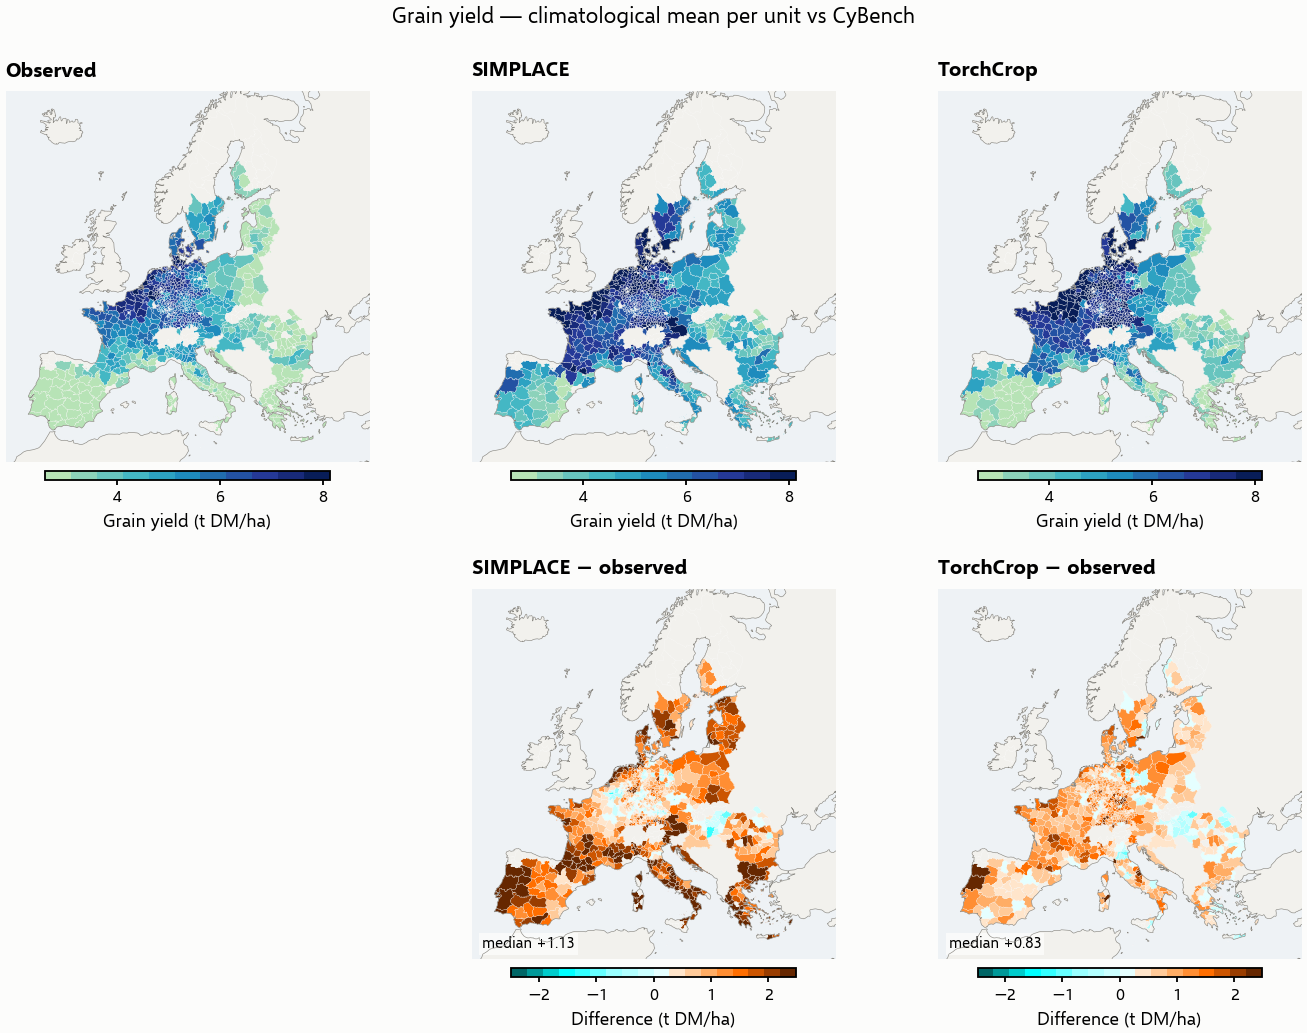

In [5]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'yield'));

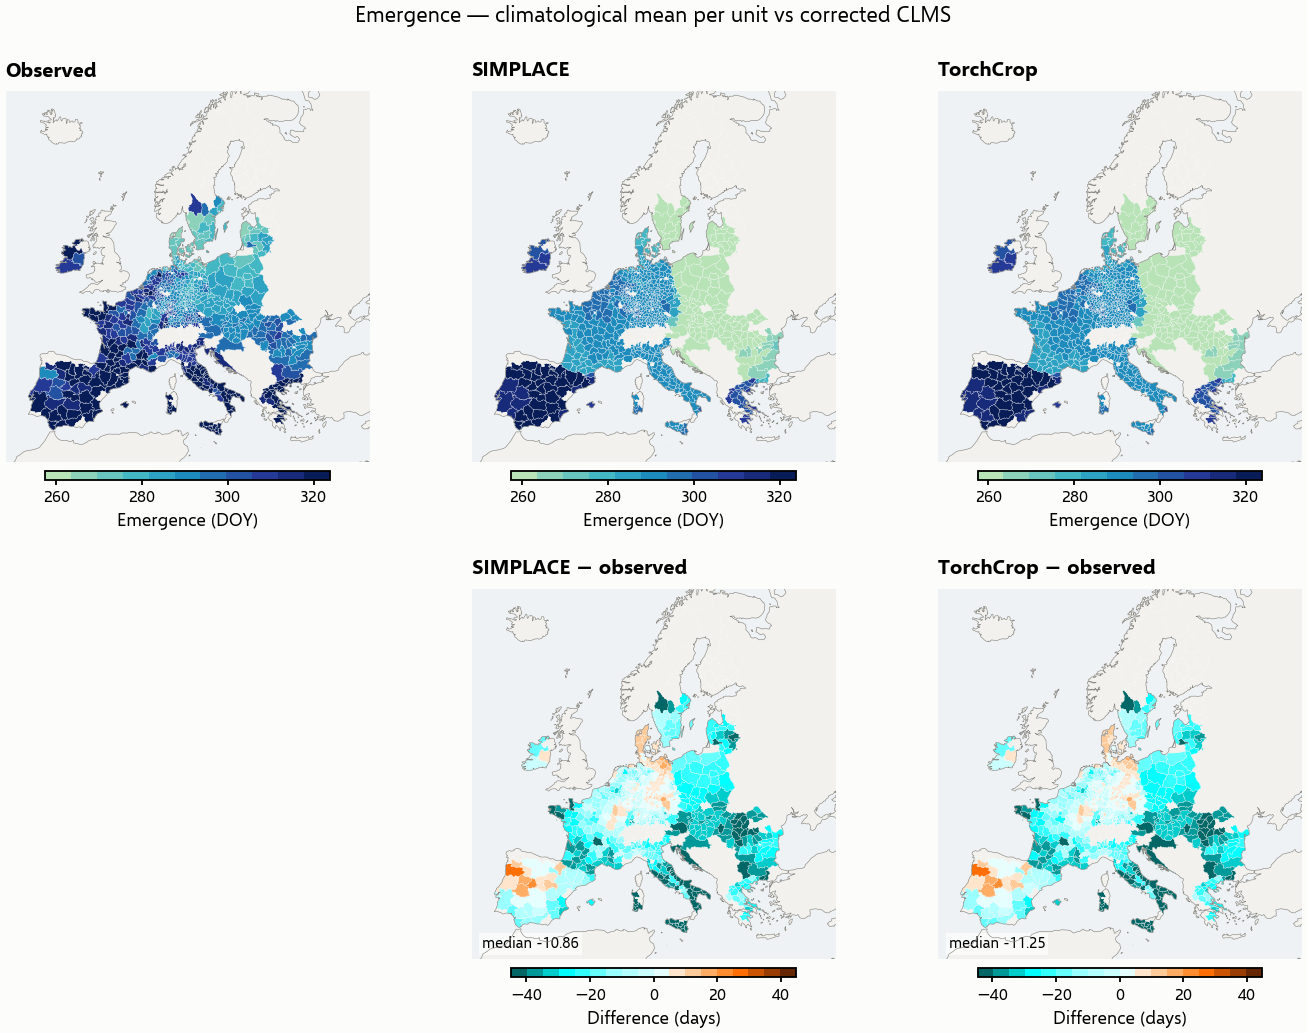

In [6]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'emergence'));

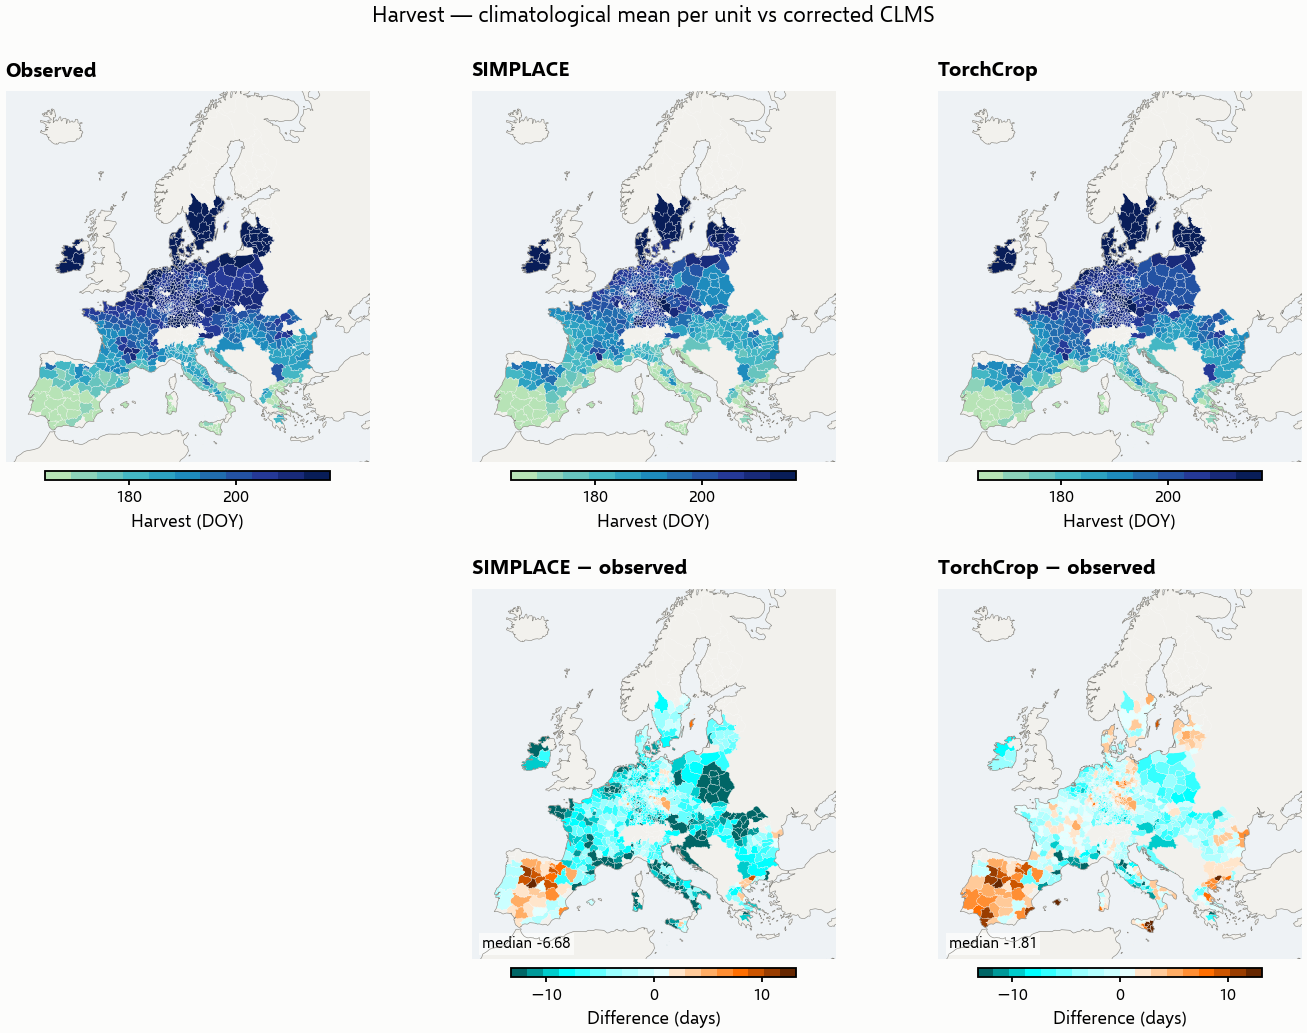

In [7]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'harvest'));

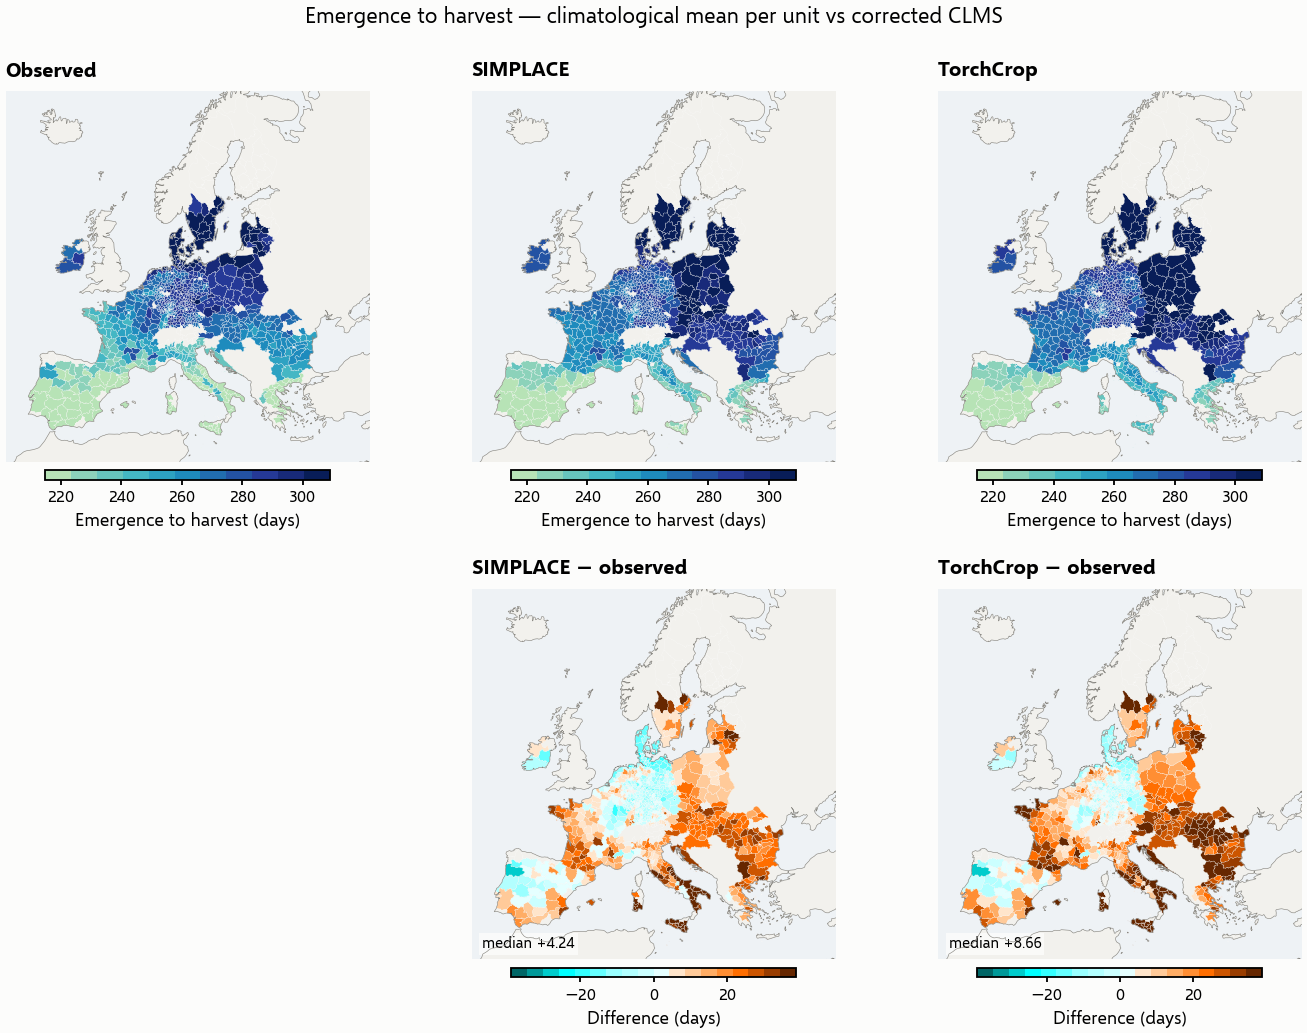

In [8]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'season_length'));

### Poster: grain-yield climatology

The yield maps above, sized for **one column of the two-column TorchCrop
poster** (7.8 in wide). Three maps, one shared colour bar; the bias maps are
replaced by what they were for:

* **Inset histogram**: the spatial distribution of unit means, the bars in the
  map's own colour steps. Model panels overlay the **observed** distribution as
  a black outline, so too much or too little spatial spread shows at a glance.
* **Metrics** (model panels), over the units both sides have:
  **bias**, the mean of model − observed; **r**, the spatial pattern
  correlation; **σ ratio**, model over observed spatial standard deviation
  (> 1: regional contrasts exaggerated).

Saved as `poster_climatology_yield.{png,pdf,svg}`.

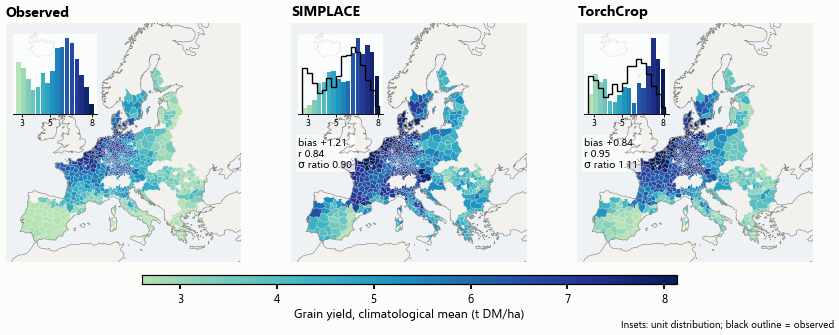

In [9]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

from cropmodelling4eu.evaluation.plots import _basemap

# Continuous version of CLIM_CMAP's range (YlGnBu from 0.28), for the poster only.
POSTER_CMAP = LinearSegmentedColormap.from_list(
    "YlGnBu_poster", plt.get_cmap("YlGnBu")(np.linspace(0.28, 1.0, 256)))
POSTER_BINS = 16
POSTER_TEXT = {"font.size": 8.1, "axes.titlesize": 9.4, "axes.titlepad": 4.0,
               "xtick.labelsize": 7.5, "axes.labelsize": 8.1}


def spatial_metrics(sim: pd.Series, obs: pd.Series) -> dict[str, float]:
    """Bias, pattern correlation and spatial-spread ratio over shared units."""
    both = pd.concat({"sim": sim, "obs": obs}, axis=1).dropna()
    return {"bias": float((both["sim"] - both["obs"]).mean()),
            "r": float(both["sim"].corr(both["obs"])),
            "sd_ratio": float(both["sim"].std() / both["obs"].std())}


def spread_inset(ax, values: pd.Series, edges: np.ndarray, reference: pd.Series | None):
    # Histogram over the empty Atlantic corner, bars in the map's colour steps.
    inset = ax.inset_axes((0.03, 0.62, 0.36, 0.33))
    counts, _ = np.histogram(values.dropna(), bins=edges)
    centres = (edges[:-1] + edges[1:]) / 2
    inset.bar(centres, counts, width=np.diff(edges) * 0.92,
              color=POSTER_CMAP(np.linspace(0, 1, len(centres))), linewidth=0)
    if reference is not None:
        ref, _ = np.histogram(reference.dropna(), bins=edges)
        inset.stairs(ref, edges, color="black", linewidth=0.9)
    inset.set_facecolor((1, 1, 1, 0.8))
    inset.set_yticks([])
    inset.set_xticks(edges[[0, len(edges) // 2, -1]].round(0))
    inset.tick_params(axis="x", labelsize=6, length=2, width=0.6, pad=1)
    inset.grid(False)
    for side in ("top", "right", "left"):
        inset.spines[side].set_visible(False)
    inset.spines["bottom"].set_linewidth(0.6)


def poster_climatology(target: prod.Target):
    clim = climatology[climatology["target"] == target.key]
    observed = clim.drop_duplicates("adm_id").set_index("adm_id")["obs"]
    sim = {m: clim[clim["model"] == m].set_index("adm_id")["sim"] for m in MODELS}
    lo, hi = np.nanpercentile(np.r_[observed, clim["sim"]], [5, 95])
    edges = np.linspace(lo, hi, POSTER_BINS + 1)
    norm = Normalize(lo, hi)
    mapped = polygons.to_crs(EUROPE_PROJECTION.proj4_init)
    unit = "DOY" if target.circular else target.unit
    with plt.rc_context(POSTER_TEXT):
        fig = plt.figure(figsize=(7.8, 3.05))
        grid = fig.add_gridspec(2, 3, height_ratios=(1, 0.04), wspace=0.03, hspace=0.1,
                                left=0.005, right=0.995, top=0.92, bottom=0.14)
        panels = [("Observed", observed, None), *[(MODELS[m], sim[m], observed) for m in MODELS]]
        for col, (title, values, reference) in enumerate(panels):
            ax = fig.add_subplot(grid[0, col], projection=EUROPE_PROJECTION)
            # Drawn here rather than with country_choropleth, which always adds
            # its own colour bar: the three maps share the one below.
            _basemap(ax, PALETTE)
            ax.grid(False)
            frame = mapped.assign(value=mapped["adm_id"].map(values))
            frame.plot(ax=ax, column="value", cmap=POSTER_CMAP, norm=norm,
                       edgecolor=PALETTE["surface"], linewidth=0.08, zorder=2,
                       missing_kwds={"color": PALETTE["land"], "edgecolor": PALETTE["surface"],
                                     "linewidth": 0.08})
            ax.set_title(title, loc="left", fontweight="bold")
            spread_inset(ax, values, edges, reference)
            if reference is not None:
                m = spatial_metrics(values, reference)
                # Under the inset, over the UK and Ireland, which have no units.
                ax.text(0.03, 0.52, f"bias {m['bias']:+.2f}\nr {m['r']:.2f}\n"
                        f"σ ratio {m['sd_ratio']:.2f}", transform=ax.transAxes,
                        ha="left", va="top", fontsize=7, color="black", linespacing=1.15,
                        bbox={"facecolor": PALETTE["surface"], "edgecolor": "none",
                              "alpha": 0.85, "pad": 1.5})
        cax = fig.add_subplot(grid[1, :].subgridspec(1, 3, width_ratios=(0.2, 1, 0.2))[0, 1])
        bar = fig.colorbar(ScalarMappable(norm, POSTER_CMAP),
                           cax=cax, orientation="horizontal")
        bar.set_label(f"{target.label}, climatological mean ({unit})", labelpad=2)
        bar.outline.set_linewidth(0.8)
        fig.text(0.995, 0.005, "Insets: unit distribution; black outline = observed",
                 ha="right", va="bottom", fontsize=6.5)
    for ext in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"poster_climatology_{target.key}.{ext}", dpi=300,
                    bbox_inches="tight")
    return fig


poster_climatology(next(t for t in prod.TARGETS if t.key == "yield"));

## 3. Per-unit scores

In [10]:
units = prod.unit_scores(paired, min_years=MIN_YEARS)
units.to_csv(TABLES / "unit_scores.csv", index=False)
(units.groupby(["target", "model"])[["n", "bias", "rmse", "ia", "mnb"]]
 .median().round(2).rename(columns=str.upper))

N   BIAS   RMSE    IA    MNB
target        model                                     
emergence     simplace    8.0 -11.06  19.66  0.38    NaN
              torchcrop   8.0 -11.51  19.84  0.37    NaN
harvest       simplace    8.0  -6.68   8.29  0.60    NaN
              torchcrop   8.0  -1.80   5.41  0.74    NaN
season_length simplace    8.0   4.24  17.40  0.46   2.02
              torchcrop   8.0   8.66  19.10  0.46   3.52
yield         simplace   21.0   1.13   1.44  0.41  22.27
              torchcrop  21.0   0.83   1.08  0.47  17.51

## 4. Maps

One figure per target: rows are the metrics, columns the two models, and
**every row shares one colour scale** so the models can be read against each
other. Units in the background colour have fewer than `MIN_YEARS` paired
seasons or no reference at all. RMSE and IA use the sequential ramp; MNB and
bias the diverging one, centred on zero (red = model high or late).

In [11]:
def metric_rows(target: prod.Target) -> list[tuple[str, str, bool]]:
    """``(column, label, diverging)`` for the three map rows of one target."""
    third = ("bias", f"Bias ({target.unit})", True) if target.circular else (
        "mnb", "MNB (%)", True)
    return [("rmse", f"RMSE ({target.unit})", False), ("ia", "IA", False), third]


def target_maps(target: prod.Target):
    scores = units[units["target"] == target.key]
    rows = metric_rows(target)
    fig, axes = plt.subplots(len(rows), len(MODELS), figsize=(9.0, 13.5),
                             subplot_kw={"projection": EUROPE_PROJECTION})
    for r, (col, label, diverging) in enumerate(rows):
        limit = _limit(scores[col])
        for c, (model, model_label) in enumerate(MODELS.items()):
            values = scores[scores["model"] == model].set_index("adm_id")[col]
            if col == "ia":
                kwargs = {"vmin": 0.0, "vmax": 1.0}
            elif diverging:
                kwargs = {"vmax": limit}
            else:
                kwargs = {"vmin": 0.0, "vmax": limit}
            country_choropleth(
                polygons, values, key_col="adm_id", diverging=diverging,
                cmap=None if diverging else SEQUENTIAL_CMAP,
                title=f"{model_label} — {label}", cbar_label=label,
                linewidth=0.15, ax=axes[r, c], **kwargs,
            )
            median = float(values.median())
            axes[r, c].text(0.03, 0.03, f"median {median:.2f}", transform=axes[r, c].transAxes,
                            fontsize=10, color="black",
                            bbox={"facecolor": PALETTE["surface"], "edgecolor": "none",
                                  "alpha": 0.85, "pad": 2})
    fig.suptitle(f"{target.label} vs {'CyBench' if target.key == 'yield' else 'corrected CLMS'}"
                 f" — per unit, ≥ {MIN_YEARS} seasons", y=0.995)
    fig.tight_layout()
    save(fig, f"map_{target.key}", FIGURES)
    return fig

### Yield

Yield MNB divides by each observed season, so a unit with a handful of very low CyBench years reads far more positive than its bias in t/ha suggests.

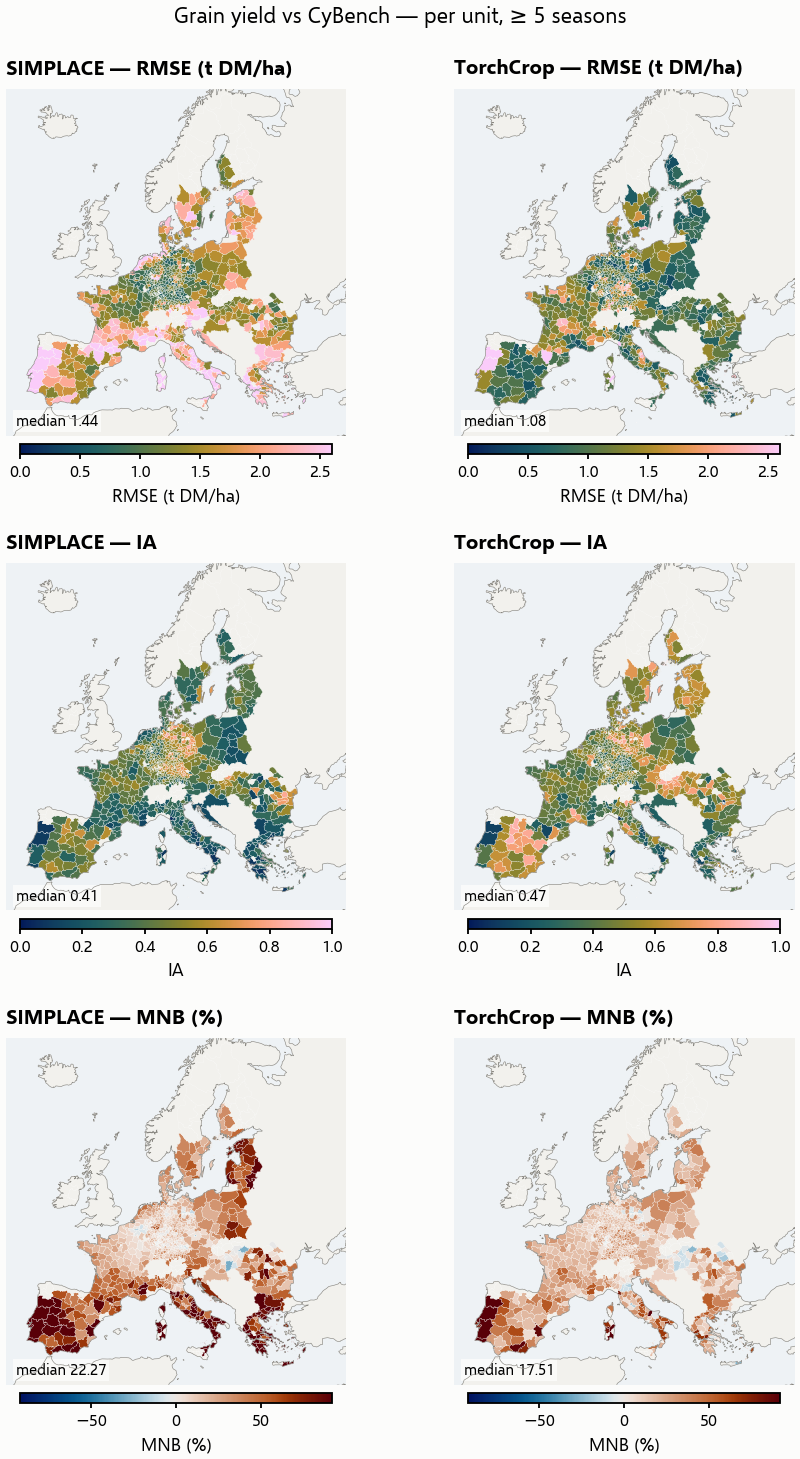

In [12]:
target_maps(next(t for t in prod.TARGETS if t.key == 'yield'));

### Emergence

CLMS emergence carries almost no interannual signal (anomaly r 0.11 against PEP725), so a low per-unit IA here says more about the reference than the model; RMSE and bias are the informative rows.

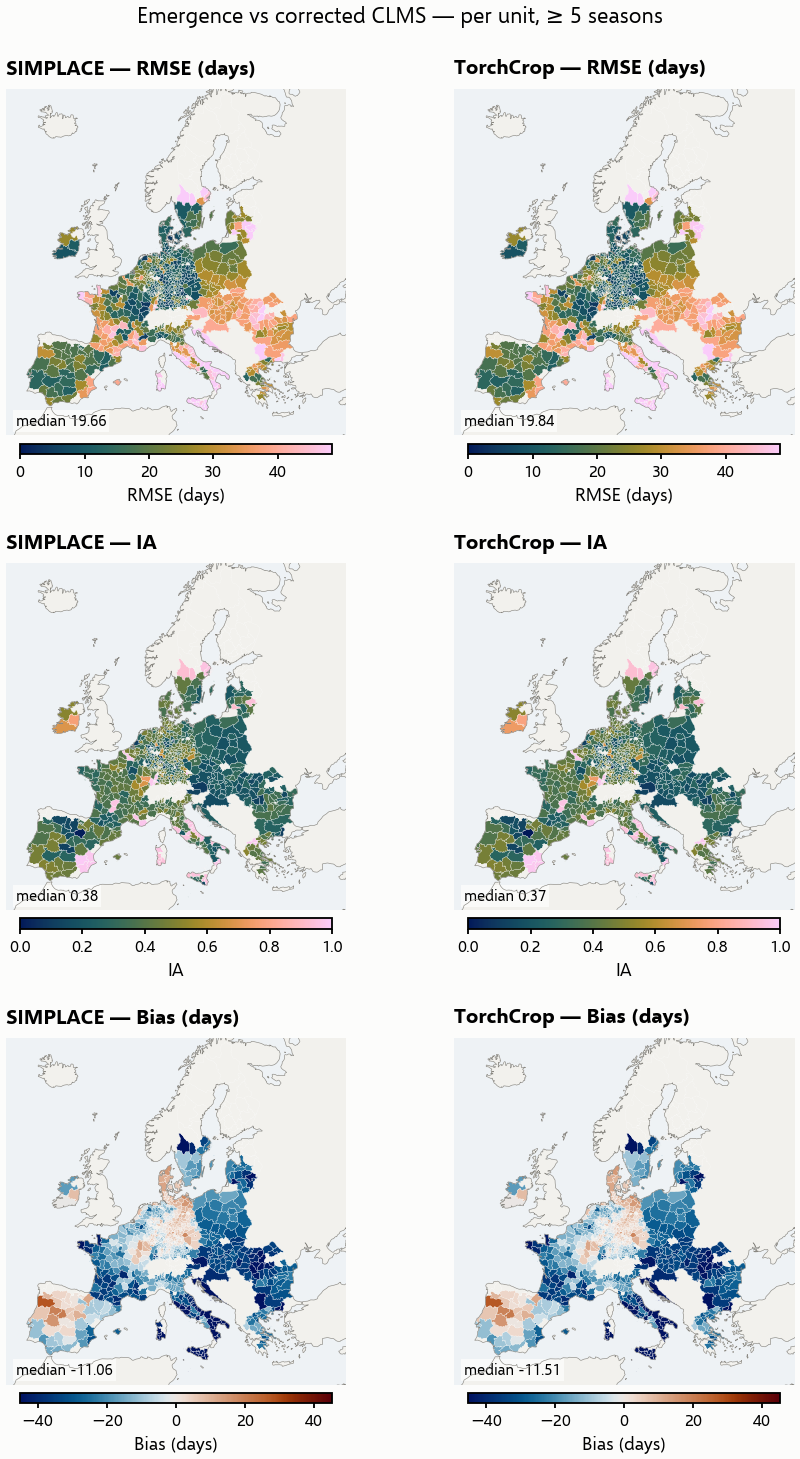

In [13]:
target_maps(next(t for t in prod.TARGETS if t.key == 'emergence'));

### Harvest

The cleanest pairing: CLMS harvest keeps real interannual skill, and the +18.7 d correction puts it on the ground scale.

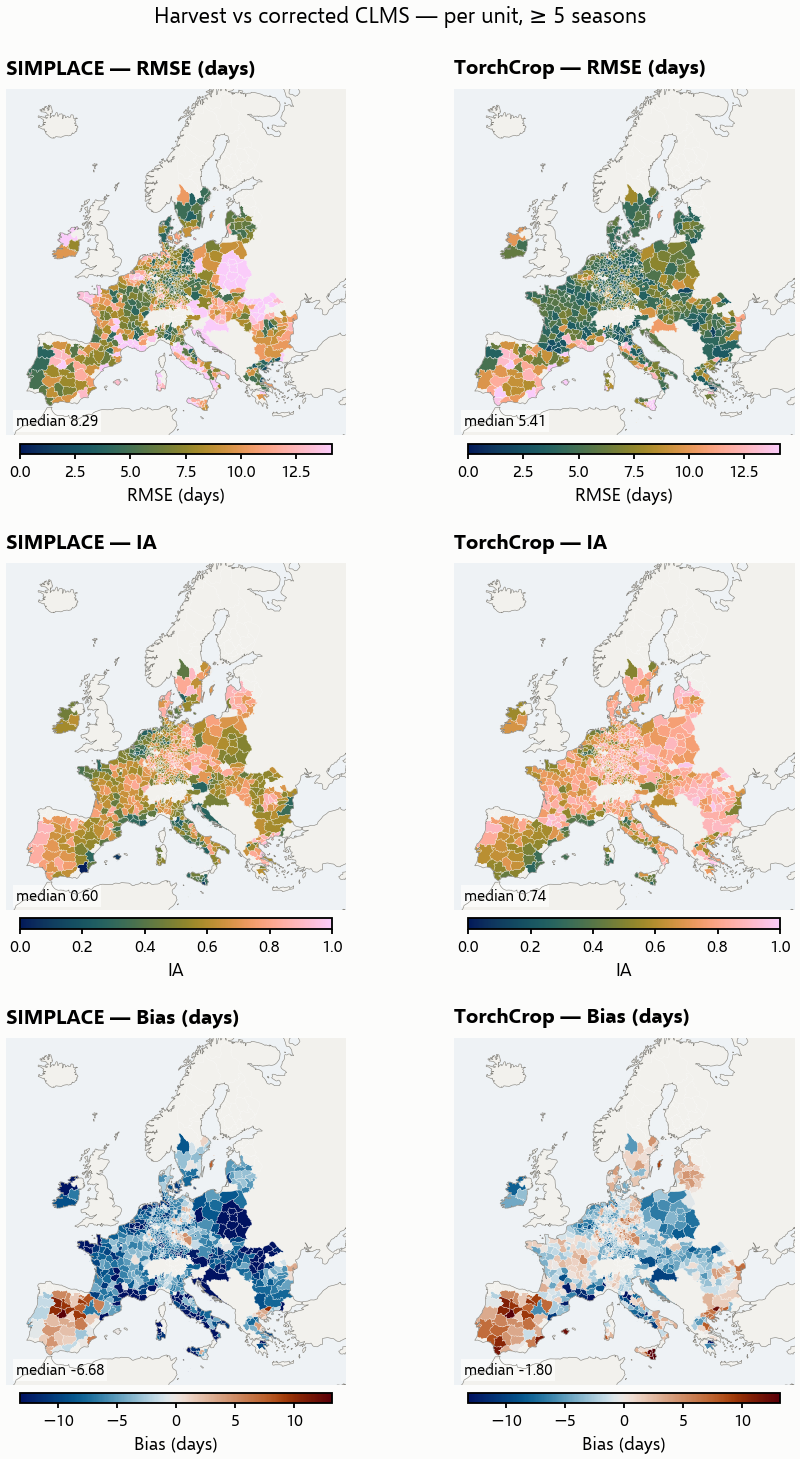

In [14]:
target_maps(next(t for t in prod.TARGETS if t.key == 'harvest'));

### Season length

Bias here is bias(harvest) − bias(emergence), so it closes against the two maps above.

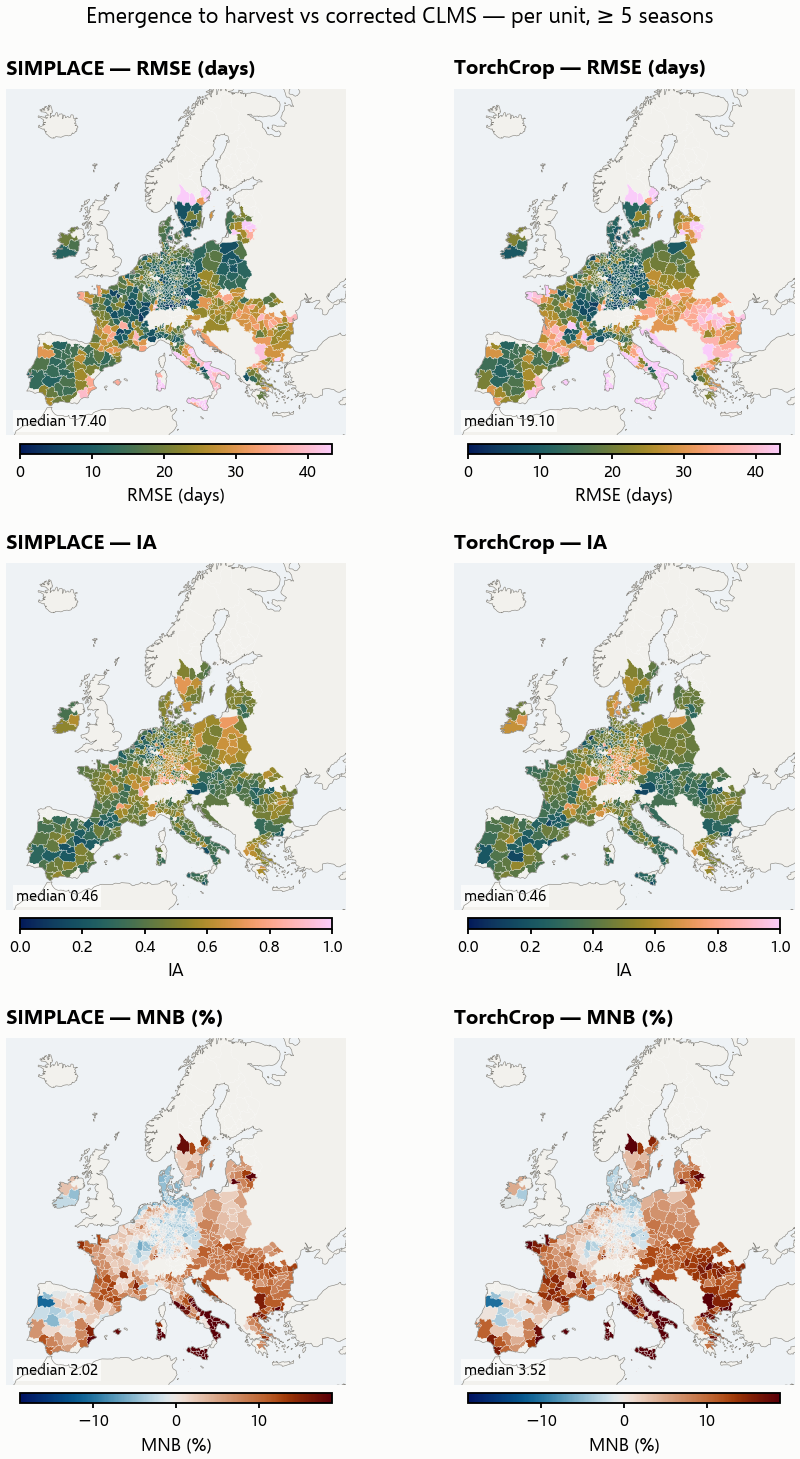

In [15]:
target_maps(next(t for t in prod.TARGETS if t.key == 'season_length'));

## 5. Time series of spatial skill

The maps score each unit over its seasons; this scores **each season over its
units**. For every year, all paired units form one sample, so RMSE, IA and MNB
say how well that year's map was reproduced: a dip in IA marks a season whose
spatial pattern the model got wrong, and a step in MNB a year it got wrong
everywhere at once. The top row is the equal-weight mean over the paired units,
observed against both models (dates as circular means). The set of units
changes from year to year — CyBench 2021 has 278 reporting units against ~700
in earlier years — so a step in the mean can be a change of composition rather
than of season; the error metrics are paired and do not carry that artefact.

Shaded years are temporally held out: no unit-year of that season was in the
calibration's `train` split. A season in which only spatially held-out units are
`test` is not shaded, since most of its units were still fitted.

In [16]:
yearly = prod.yearly_scores(paired)
yearly.to_csv(TABLES / "yearly_scores.csv", index=False)
# The poster's encoding: SIMPLACE a thick grey line (the reference
# implementation), TorchCrop teal with circles, observed black.
COLOURS = {"simplace": PALETTE["simplace"], "torchcrop": PALETTE["torchcrop"]}
LINES = {"simplace": {"lw": 2.6, "marker": None},
         "torchcrop": {"lw": 1.4, "marker": "o", "ms": 3.5}}


def target_timeseries(target: prod.Target):
    scores = yearly[yearly["target"] == target.key].sort_values("year")
    rows = [("obs_mean", f"Mean ({target.unit})", None), *metric_rows(target)]
    fig, axes = plt.subplots(len(rows), 1, figsize=(8.0, 9.5), sharex=True)
    held = scores.loc[scores["held_out"], "year"].unique()
    for ax, (col, label, diverging) in zip(axes, rows):
        for year in held:
            ax.axvspan(year - 0.5, year + 0.5, color=PALETTE["grid"], zorder=0, lw=0)
        if col == "obs_mean":
            obs = scores.drop_duplicates("year")
            ax.plot(obs["year"], obs["obs_mean"], color="black", marker="s",
                    ms=3, lw=1.4, label="observed", zorder=4)
            for model, model_label in MODELS.items():
                block = scores[scores["model"] == model]
                ax.plot(block["year"], block["sim_mean"], color=COLOURS[model],
                        label=model_label, zorder=3, **LINES[model])
            ax.legend(frameon=False, ncols=3, loc="best")
        else:
            for model, model_label in MODELS.items():
                block = scores[scores["model"] == model]
                ax.plot(block["year"], block[col], color=COLOURS[model], label=model_label,
                        zorder=3, **LINES[model])
            if diverging:
                ax.axhline(0.0, color="black", lw=0.8, zorder=1)
            if col == "ia":
                ax.set_ylim(0.0, 1.0)
        ax.set_ylabel(label)
    axes[-1].set_xlabel("Harvest year")
    axes[-1].xaxis.get_major_locator().set_params(integer=True)
    fig.suptitle(f"{target.label} — spatial skill per season "
                 f"(units per year: {int(scores['n'].median())} median)", y=0.995)
    fig.tight_layout()
    save(fig, f"timeseries_{target.key}", FIGURES)
    return fig

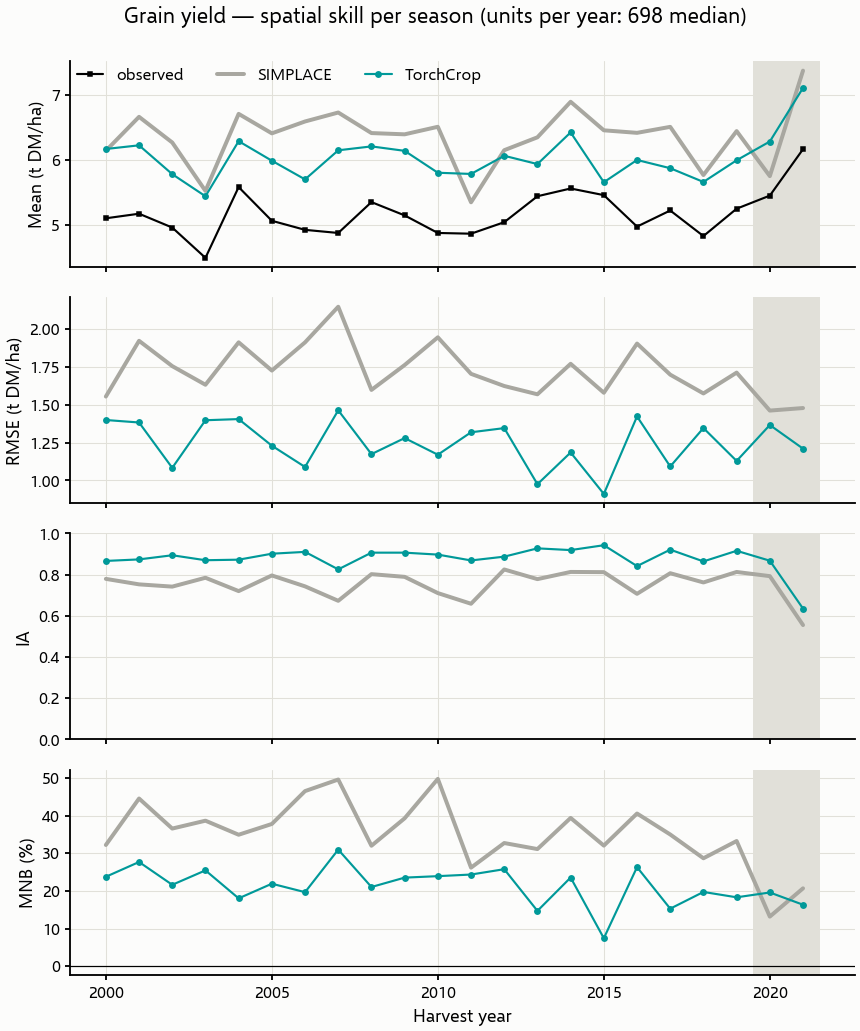

In [17]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'yield'));

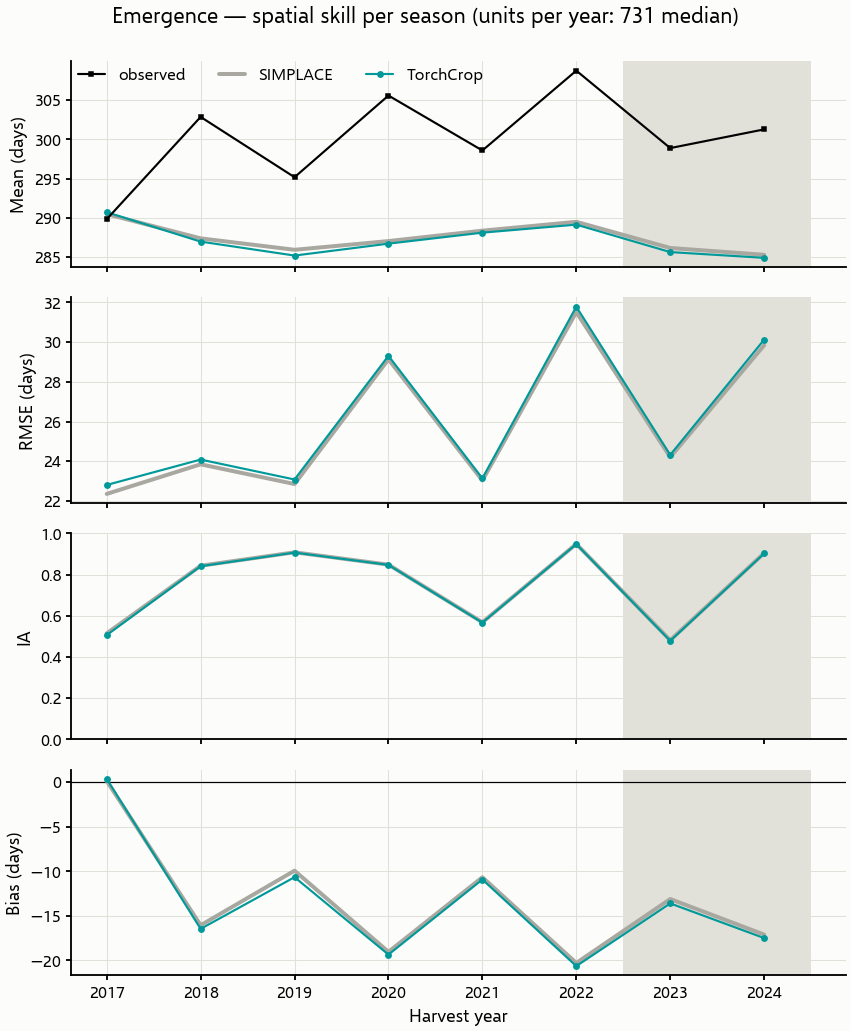

In [18]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'emergence'));

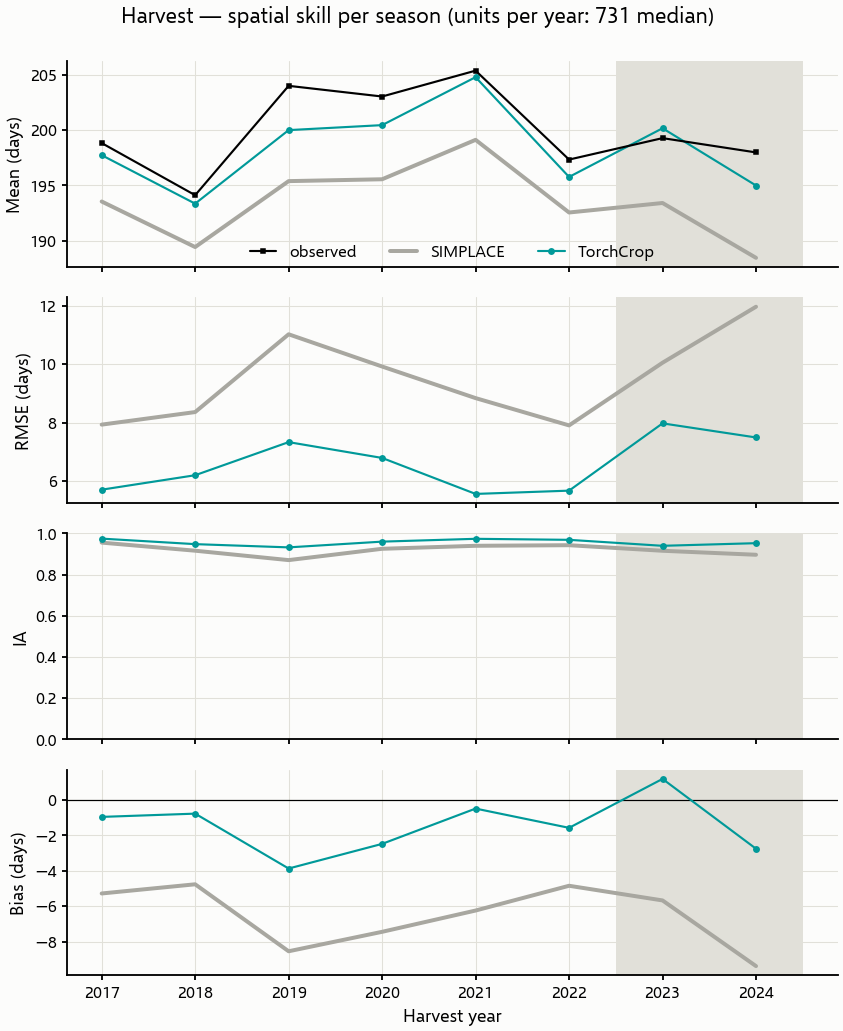

In [19]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'harvest'));

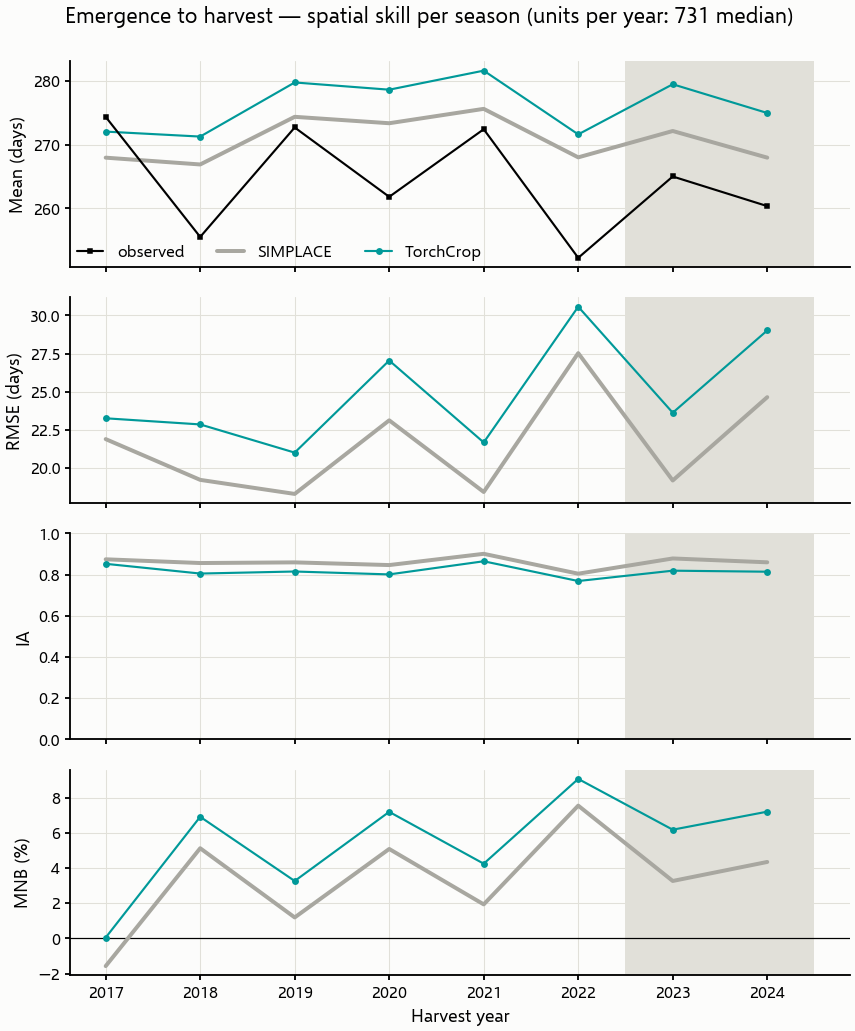

In [20]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'season_length'));

## 6. Pooled scores by calibration split

Every unit-year pooled. `train` is what the parameters were fitted on;
`val`/`test` are the held-out years and units. A pooled IA includes the
between-unit spread — getting the north-to-south gradient right — so it reads
well above the per-unit medians in §3, which only see each unit's own seasons.

In [21]:
pooled = prod.pooled_scores(paired)
pooled.to_csv(TABLES / "pooled_scores.csv", index=False)
order = {"all": 0, "train": 1, "val": 2, "test": 3, "unused": 4}
(pooled.assign(_o=pooled["split"].map(order)).sort_values(["target", "model", "_o"])
 .drop(columns="_o").set_index(["target", "model", "split"]).round(2)
 .rename(columns=str.upper))

N   BIAS   RMSE    IA    MNB
target        model     split                                     
emergence     simplace  all      5811.0 -13.64  26.19  0.89    NaN
                        train    3591.0 -13.65  26.26  0.90    NaN
                        val       666.0 -13.37  23.95  0.50    NaN
                        test     1554.0 -13.75  26.94  0.88    NaN
              torchcrop all      5811.0 -14.00  26.42  0.88    NaN
                        train    3591.0 -13.97  26.50  0.90    NaN
                        val       666.0 -13.83  24.06  0.49    NaN
                        test     1554.0 -14.13  27.20  0.88    NaN
harvest       simplace  all      5811.0  -6.56   9.65  0.92    NaN
                        train    3591.0  -6.41   9.20  0.93    NaN
                        val       666.0  -5.98  10.20  0.92    NaN
                        test     1554.0  -7.15  10.39  0.92    NaN
              torchcrop all      5811.0  -1.45   6.69  0.96    NaN
                        train    3591.0  -1.89   6.24  0.96    NaN
                        val       666.0   0.92   7.92  0.94    NaN
                        test     1554.0  -1.47   7.11  0.96    NaN
season_length simplace  all      5811.0   6.89  21.79  0.86   3.50
                        train    3591.0   7.01  21.97  0.86   3.53
                        val       666.0   7.22  19.04  0.88   3.28
                        test     1554.0   6.48  22.45  0.86   3.54
              torchcrop all      5811.0  12.35  25.18  0.82   5.67
                        train    3591.0  11.84  25.00  0.82   5.45
                        val       666.0  14.58  23.50  0.82   6.19
                        test     1554.0  12.54  26.27  0.82   5.98
yield         simplace  all     14929.0   1.18   1.74  0.77  35.70
                        train   12161.0   1.23   1.76  0.77  37.19
                        val       564.0   0.29   1.46  0.79  13.21
                        test     2197.0   1.14   1.72  0.76  33.24
                        unused      7.0   1.08   1.23  0.35  33.18
              torchcrop all     14923.0   0.85   1.25  0.89  21.46
                        train   12161.0   0.85   1.25  0.89  21.56
                        val       564.0   0.81   1.37  0.87  19.49
                        test     2197.0   0.89   1.25  0.89  21.42
                        unused      1.0   0.64   0.64   NaN  20.78